# SNOTEL download: Middle Boise River Basin

Downloads full period-of-record **daily** data for 5 SNOTEL sites (by Site ID) from the NRCS AWDB REST API and saves one combined CSV.

Run the cells top to bottom. In VS Code, pick a Python kernel (top right) first.

## 1. Install / import

In [5]:
# Uncomment if requests/pandas/matplotlib aren't installed in your kernel
# %pip install requests pandas matplotlib

import time
import requests
import pandas as pd

## 2. Sites and variables

In [6]:
BASE = "https://wcc.sc.egov.usda.gov/awdbRestApi/services/v1"
OUT_CSV = "snotel_boise.csv"

# (site_id, state, name, basin)
SITES = [
    # Middle Boise River Basin (Idaho)
    (637, "ID", "Mores Creek Summit",   "Middle Boise River"),
    (830, "ID", "Trinity Mountain",     "Middle Boise River"),
    (306, "ID", "Atlanta Summit",       "Middle Boise River"),
    (496, "ID", "Graham Guard Station", "Middle Boise River"),
    (550, "ID", "Jackson Peak",         "Middle Boise River"),
]

# WTEQ=SWE (in), PREC=accum. precip (in), PRCP=incremental precip (in),
# TOBS/TMAX/TMIN/TAVG=air temp (F), RHUM/RHUMV=relative humidity (%),
# SMS=soil moisture (% by depth), PRES=pressure (rare on SNOTEL)
WANTED = ["WTEQ", "PREC", "PRCP", "TOBS", "TMAX", "TMIN", "TAVG",
          "RHUM", "RHUMV", "SMS", "PRES"]

## 3. Helper functions

In [7]:
def get(path, params, tries=4):
    for i in range(tries):
        try:
            r = requests.get(f"{BASE}/{path}", params=params, timeout=120)
            r.raise_for_status()
            return r.json()
        except Exception:
            if i == tries - 1:
                raise
            time.sleep(2 * (i + 1))


def col_name(code, depth):
    if depth is None:
        return code
    d = int(depth) if float(depth).is_integer() else depth
    return f"{code}_{d}in"   # e.g. SMS_-2in = 2 in below surface


def fetch_site(site_id, state, name, basin):
    triplet = f"{site_id}:{state}:SNTL"

    # Station metadata: which daily elements exist + start of record
    meta = get("stations", {"stationTriplets": triplet, "returnStationElements": "true"})
    if not meta:
        print(f"  !! no metadata for {triplet}")
        return None
    st = meta[0]
    begin = str(st.get("beginDate", "1980-01-01"))[:10]
    end = pd.Timestamp.today().strftime("%Y-%m-%d")

    combos = set()
    for el in st.get("stationElements", []):
        code = el.get("elementCode")
        if code in WANTED and el.get("durationName") == "DAILY":
            hd = el.get("heightDepth")
            depth = hd.get("value") if isinstance(hd, dict) else None
            combos.add((code, depth, el.get("ordinal", 1)))
    if not combos:
        print(f"  !! no wanted daily elements for {triplet}")
        return None

    cols = {}   # column name -> Series (names guaranteed unique)
    for code, depth, ordinal in sorted(combos, key=lambda x: (x[0], x[1] or 0, x[2])):
        el_str = code if depth is None else f"{code}:{int(depth)}:{ordinal}"
        try:
            data = get("data", {
                "stationTriplets": triplet, "elements": el_str, "duration": "DAILY",
                "beginDate": begin, "endDate": end, "periodRef": "END", "returnFlags": "false",
            })
        except Exception as e:
            print(f"  !! {triplet} {el_str} failed: {e}")
            continue
        for block in data:
            for series in block.get("data", []):
                vals = series.get("values", [])
                if not vals:
                    continue
                se = series.get("stationElement") or {}
                hd = se.get("heightDepth")
                d = hd.get("value") if isinstance(hd, dict) else depth
                name_ = col_name(code, d)
                if name_ in cols:                       # same variable/depth already seen
                    name_ = f"{name_}_ord{se.get('ordinal', ordinal)}"
                base, k = name_, 2
                while name_ in cols:                    # last-resort uniqueness
                    name_ = f"{base}_{k}"; k += 1
                cols[name_] = pd.Series({v["date"]: v.get("value") for v in vals})
    if not cols:
        return None

    df = pd.DataFrame(cols)
    df = df.loc[:, ~df.columns.duplicated()]
    df.index = pd.to_datetime(df.index)
    df.index.name = "date"
    df = df.reset_index()
    df.insert(1, "site_id", site_id)
    df.insert(2, "site_name", name)
    df.insert(3, "basin", basin)
    df.insert(4, "state", state)
    return df

## 4. Download (takes a few minutes)

In [8]:
out = []
for sid, state, name, basin in SITES:
    print(f"Fetching {sid} {name} ({state}) ...")
    df_site = fetch_site(sid, state, name, basin)
    if df_site is not None:
        print(f"  {len(df_site):,} rows, {df_site['date'].min().date()} -> {df_site['date'].max().date()}")
        out.append(df_site)

# --- Water year: Oct 1 -> Sep 30, named for the year it ENDS (Oct 1 2019 = WY2020) ---
df = pd.concat(out, ignore_index=True, sort=False)
df["water_year"] = df["date"].dt.year + (df["date"].dt.month >= 10).astype(int)
wy_start = pd.to_datetime((df["water_year"] - 1).astype(str) + "-10-01")
df["day_of_water_year"] = (df["date"] - wy_start).dt.days + 1   # Oct 1 = 1

# --- Annual (water-year) values, repeated on every row of that site/water year ---
# SWE:    peak SWE + date, total SWE accumulated, April 1 SWE
# precip: total water-year precipitation = max of accumulated PREC (it resets Oct 1)
df = df.sort_values(["site_id", "water_year", "date"]).reset_index(drop=True)
key = [df["site_id"], df["water_year"]]
g = df.groupby(["site_id", "water_year"])

if "WTEQ" in df:
    df["annual_swe_peak_in"] = g["WTEQ"].transform("max")
    peak_date = (df.loc[df["WTEQ"].notna()]
                   .sort_values("WTEQ", ascending=False)
                   .drop_duplicates(["site_id", "water_year"])
                   .set_index(["site_id", "water_year"])["date"])
    df["annual_swe_peak_date"] = [peak_date.get((a, b)) for a, b in zip(df["site_id"], df["water_year"])]

    # Total SWE accumulated = sum of positive day-to-day SWE gains in the water year
    # (all snow water added, even if some later melted; small sensor noise adds a little)
    gain = g["WTEQ"].diff().clip(lower=0)
    df["annual_swe_accumulated_in"] = gain.groupby(key).transform("sum")

    # April 1 SWE (April 1 of the year the water year ends)
    apr1 = (df[(df["date"].dt.month == 4) & (df["date"].dt.day == 1)]
            .set_index(["site_id", "water_year"])["WTEQ"])
    df["apr1_swe_in"] = [apr1.get((a, b)) for a, b in zip(df["site_id"], df["water_year"])]

if "PREC" in df:
    df["annual_precip_in"] = g["PREC"].transform("max")

df["days_of_data_in_wy"] = g["date"].transform("count")   # <365 => partial water year

id_cols = ["water_year", "day_of_water_year", "date", "site_id", "site_name", "basin", "state"]
var_cols = sorted(c for c in df.columns if c not in id_cols)
# Sorted by site, then water year, then day within the water year
df = df[id_cols + var_cols].sort_values(["site_id", "water_year", "date"]).reset_index(drop=True)
df.to_csv(OUT_CSV, index=False)

# One-row-per-site-per-water-year summary
annual_cols = [c for c in ["annual_swe_peak_in", "annual_swe_peak_date", "annual_swe_accumulated_in", "apr1_swe_in", "annual_precip_in", "days_of_data_in_wy"] if c in df]
annual = df.groupby(["site_id", "site_name", "water_year"])[annual_cols].first().reset_index()
annual.to_csv("snotel_boise_annual_by_water_year.csv", index=False)
print(f"\nSaved {OUT_CSV}: {len(df):,} rows, {len(var_cols)} variable columns")

Fetching 637 Mores Creek Summit (ID) ...
  17,106 rows, 1978-09-30 -> 2026-11-03
Fetching 830 Trinity Mountain (ID) ...
  16,958 rows, 1979-03-05 -> 2026-11-03
Fetching 306 Atlanta Summit (ID) ...
  17,543 rows, 1978-10-01 -> 2026-11-03
Fetching 496 Graham Guard Station (ID) ...
  17,533 rows, 1978-10-01 -> 2026-11-03
Fetching 550 Jackson Peak (ID) ...
  16,787 rows, 1980-08-11 -> 2026-11-03

Saved snotel_boise.csv: 85,927 rows, 21 variable columns


## 5. What data does each site have?

In [9]:
# Count of non-missing days per site and variable
availability = df.groupby(["site_id", "site_name"])[var_cols].count()
availability

,,PRCP,PREC,RHUMV,TAVG,TAVG_ord1,TMAX,TMAX_ord1,TMIN,TMIN_ord1,TOBS,...,TOBS_ord1_2,WTEQ,WTEQ_ord1,WTEQ_ord1_2,annual_precip_in,annual_swe_accumulated_in,annual_swe_peak_date,annual_swe_peak_in,apr1_swe_in,days_of_data_in_wy
site_id,site_name,,,,,,,,,,,,,,,,,,,,,
306,Atlanta Summit,16716,16722,0,13670,0,13714,0,13662,0,16703,...,0,16434,0,0,17189,17543,17189,17189,16071,17543
496,Graham Guard Station,16830,16838,0,13860,13860,13861,13861,13855,13855,16139,...,0,16828,16828,16828,17175,17533,17185,17185,16793,17533
550,Jackson Peak,16447,16449,0,13807,0,13798,0,13791,0,16520,...,0,16334,0,0,16449,16787,16737,16737,16050,16787
637,Mores Creek Summit,16284,16297,1129,15601,0,15614,0,15577,0,16416,...,16416,16293,0,0,16798,17106,16539,16539,16258,17106
830,Trinity Mountain,16841,16847,0,13843,0,13846,0,13838,0,16469,...,0,16785,0,0,16847,16958,16946,16946,16801,16958


In [10]:
df.head()

,water_year,day_of_water_year,date,site_id,site_name,basin,state,PRCP,PREC,RHUMV,...,TOBS_ord1_2,WTEQ,WTEQ_ord1,WTEQ_ord1_2,annual_precip_in,annual_swe_accumulated_in,annual_swe_peak_date,annual_swe_peak_in,apr1_swe_in,days_of_data_in_wy
0,1979,1,1978-10-01,306,Atlanta Summit,Middle Boise River,ID,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,35.5,0.0,NaT,NaN,NaN,354
1,1979,2,1978-10-02,306,Atlanta Summit,Middle Boise River,ID,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,35.5,0.0,NaT,NaN,NaN,354
2,1979,3,1978-10-03,306,Atlanta Summit,Middle Boise River,ID,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,35.5,0.0,NaT,NaN,NaN,354
3,1979,4,1978-10-04,306,Atlanta Summit,Middle Boise River,ID,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,35.5,0.0,NaT,NaN,NaN,354
4,1979,5,1978-10-05,306,Atlanta Summit,Middle Boise River,ID,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,35.5,0.0,NaT,NaN,NaN,354


## Data by water year

In [11]:
# Annual summary: peak SWE and total precip per site per water year
annual

,site_id,site_name,water_year,annual_swe_peak_in,annual_swe_peak_date,annual_swe_accumulated_in,apr1_swe_in,annual_precip_in,days_of_data_in_wy
0,306,Atlanta Summit,1979,NaN,NaT,0.0,NaN,35.5,354
1,306,Atlanta Summit,1980,0.0,1980-09-30,0.0,NaN,NaN,354
2,306,Atlanta Summit,1981,18.3,1981-04-13,19.6,17.6,37.1,365
3,306,Atlanta Summit,1982,0.1,1982-09-30,0.1,NaN,64.2,365
4,306,Atlanta Summit,1983,47.3,1983-04-30,32.6,NaN,60.9,365
...,...,...,...,...,...,...,...,...,...
240,830,Trinity Mountain,2023,43.8,2023-04-23,44.8,43.0,57.2,365
241,830,Trinity Mountain,2024,30.0,2024-04-09,31.7,28.8,39.4,366
242,830,Trinity Mountain,2025,40.0,2025-04-09,40.5,39.8,46.9,365
243,830,Trinity Mountain,2026,23.6,2026-04-18,27.6,22.0,40.6,365


In [12]:
# Days of data per site per water year (a full water year = 365/366 days)
days_per_wy = df.pivot_table(index="water_year", columns="site_name",
                             values="date", aggfunc="count")
days_per_wy

site_name,Atlanta Summit,Graham Guard Station,Jackson Peak,Mores Creek Summit,Trinity Mountain
water_year,,,,,
1978,NaN,NaN,NaN,1.0,NaN
1979,354.0,348.0,NaN,259.0,12.0
1980,354.0,358.0,50.0,307.0,111.0
1981,365.0,365.0,288.0,247.0,365.0
1982,365.0,365.0,365.0,246.0,365.0
1983,365.0,357.0,365.0,320.0,365.0
1984,366.0,366.0,345.0,366.0,366.0
1985,365.0,365.0,365.0,365.0,365.0
1986,365.0,365.0,365.0,365.0,365.0


In [13]:
# Example: pull one site + water year
df[(df["site_id"] == 637) & (df["water_year"] == 2023)].head()

,water_year,day_of_water_year,date,site_id,site_name,basin,state,PRCP,PREC,RHUMV,...,TOBS_ord1_2,WTEQ,WTEQ_ord1,WTEQ_ord1_2,annual_precip_in,annual_swe_accumulated_in,annual_swe_peak_date,annual_swe_peak_in,apr1_swe_in,days_of_data_in_wy
67488,2023,1,2022-10-01,637,Mores Creek Summit,Middle Boise River,ID,0.0,0.0,NaN,...,41.2,0.0,NaN,NaN,48.2,39.4,2023-04-08,37.4,36.4,351
67489,2023,2,2022-10-02,637,Mores Creek Summit,Middle Boise River,ID,0.0,0.0,NaN,...,45.0,0.0,NaN,NaN,48.2,39.4,2023-04-08,37.4,36.4,351
67490,2023,3,2022-10-03,637,Mores Creek Summit,Middle Boise River,ID,0.0,0.0,NaN,...,44.4,0.0,NaN,NaN,48.2,39.4,2023-04-08,37.4,36.4,351
67491,2023,4,2022-10-04,637,Mores Creek Summit,Middle Boise River,ID,0.0,0.0,NaN,...,46.0,0.0,NaN,NaN,48.2,39.4,2023-04-08,37.4,36.4,351
67492,2023,5,2022-10-05,637,Mores Creek Summit,Middle Boise River,ID,0.0,0.0,NaN,...,47.1,0.0,NaN,NaN,48.2,39.4,2023-04-08,37.4,36.4,351


In [ ]:
# Optional: also write one CSV per water year (WY1981.csv, WY1982.csv, ...)
# import os; os.makedirs("by_water_year", exist_ok=True)
# for wy, g in df.groupby("water_year"):
#     g.to_csv(f"by_water_year/WY{wy}.csv", index=False)

## 6. Quick plot (SWE by site)

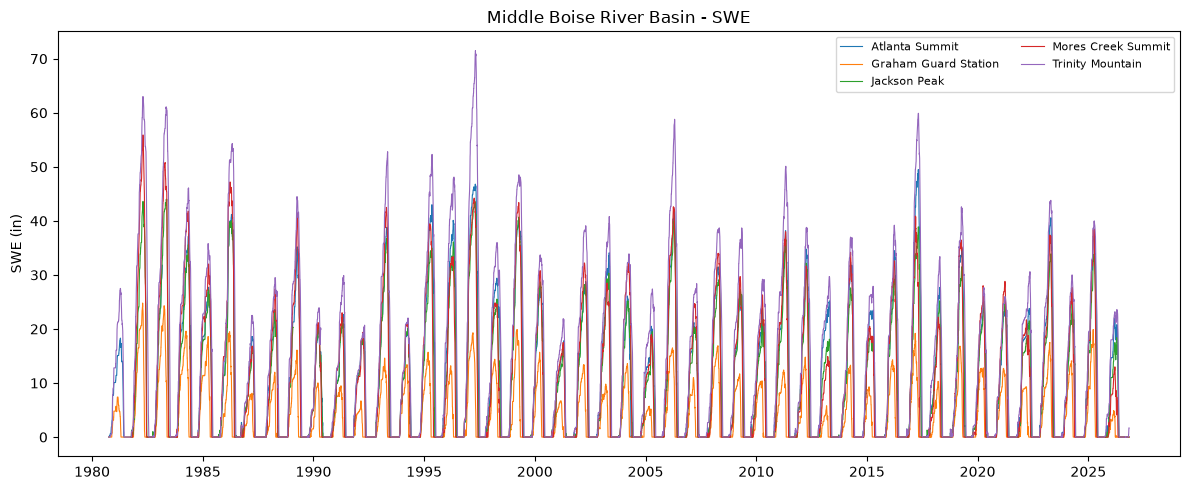

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 5))
for name, g in df.groupby("site_name"):
    if "WTEQ" in g:
        ax.plot(g["date"], g["WTEQ"], label=name, lw=0.8)
ax.set_title("Middle Boise River Basin - SWE"); ax.set_ylabel("SWE (in)"); ax.legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.show()